<a href="https://colab.research.google.com/github/Dhilip-24/Crypto-currency-price-prediction/blob/main/Crypto_currency_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

zip_path = '/content/archive.zip'
extract_path = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Files in extracted folder:")
for root, dirs, files in os.walk(extract_path):
    for file in files[:20]:  # Print first 20 files
        print(os.path.join(root, file))

Files in extracted folder:
/content/extracted_data/coin_Litecoin.csv
/content/extracted_data/coin_Tron.csv
/content/extracted_data/coin_ChainLink.csv
/content/extracted_data/coin_Solana.csv
/content/extracted_data/coin_Tether.csv
/content/extracted_data/coin_XRP.csv
/content/extracted_data/coin_Stellar.csv
/content/extracted_data/coin_Polkadot.csv
/content/extracted_data/coin_EOS.csv
/content/extracted_data/coin_Dogecoin.csv
/content/extracted_data/coin_Monero.csv
/content/extracted_data/coin_Bitcoin.csv
/content/extracted_data/coin_WrappedBitcoin.csv
/content/extracted_data/coin_BinanceCoin.csv
/content/extracted_data/coin_Cardano.csv
/content/extracted_data/coin_Aave.csv
/content/extracted_data/coin_Cosmos.csv
/content/extracted_data/coin_Iota.csv
/content/extracted_data/coin_Ethereum.csv
/content/extracted_data/coin_Uniswap.csv


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Load the Bitcoin dataset
file_path = '/content/extracted_data/coin_Bitcoin.csv'
df = pd.read_csv(file_path)

# Display basic information
print("Original Dataset Shape:", df.shape)
print(df.head())

# Convert Date column to datetime and sort chronologically
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Handle missing values if any
print("Missing values per column:\n", df.isnull().sum())
df = df.ffill().bfill()

# Select a manageable subset of 2000 consecutive daily records (e.g., the last 2000 days)
subset_df = df.tail(2000).reset_index(drop=True)
print("\nSubset shape:", subset_df.shape)

# We will use 'Close' price for the prediction
close_prices = subset_df[['Close']].values

# Normalize numerical features using MinMaxScaler (scale between 0 and 1)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_close = scaler.fit_transform(close_prices)

print("Successfully normalized the closing prices. Sample values:\n", scaled_close[:5])

Original Dataset Shape: (2991, 10)
   SNo     Name Symbol                 Date        High         Low  \
0    1  Bitcoin    BTC  2013-04-29 23:59:59  147.488007  134.000000   
1    2  Bitcoin    BTC  2013-04-30 23:59:59  146.929993  134.050003   
2    3  Bitcoin    BTC  2013-05-01 23:59:59  139.889999  107.720001   
3    4  Bitcoin    BTC  2013-05-02 23:59:59  125.599998   92.281898   
4    5  Bitcoin    BTC  2013-05-03 23:59:59  108.127998   79.099998   

         Open       Close  Volume     Marketcap  
0  134.444000  144.539993     0.0  1.603769e+09  
1  144.000000  139.000000     0.0  1.542813e+09  
2  139.000000  116.989998     0.0  1.298955e+09  
3  116.379997  105.209999     0.0  1.168517e+09  
4  106.250000   97.750000     0.0  1.085995e+09  
Missing values per column:
 SNo          0
Name         0
Symbol       0
Date         0
High         0
Low          0
Open         0
Close        0
Volume       0
Marketcap    0
dtype: int64

Subset shape: (2000, 10)
Successfully normaliz

Sequence shapes -> X: (1993, 7, 1), y: (1993, 1)
Train size: 1594, Test size: 399


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0011 - val_loss: 0.0043
Epoch 2/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1830e-04 - val_loss: 0.0014
Epoch 3/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0490e-04 - val_loss: 0.0014
Epoch 4/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0635e-04 - val_loss: 0.0014
Epoch 5/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.2559e-05 - val_loss: 0.0017
Epoch 6/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.8556e-05 - val_loss: 0.0015
Epoch 7/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.7723e-05 - val_loss: 0.0013
Epoch 8/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.9811e-05 - val_loss: 0.0014
Epoch 9/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.7610e-05 - val_loss: 0.0014
Epoch 10/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.7515e-05 - val_loss: 0.0014
Epoch 11/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.2123e-05 - val_loss: 0.0015
Epoch 12/25
50/50 ━━━━━━━━━━━━━━━

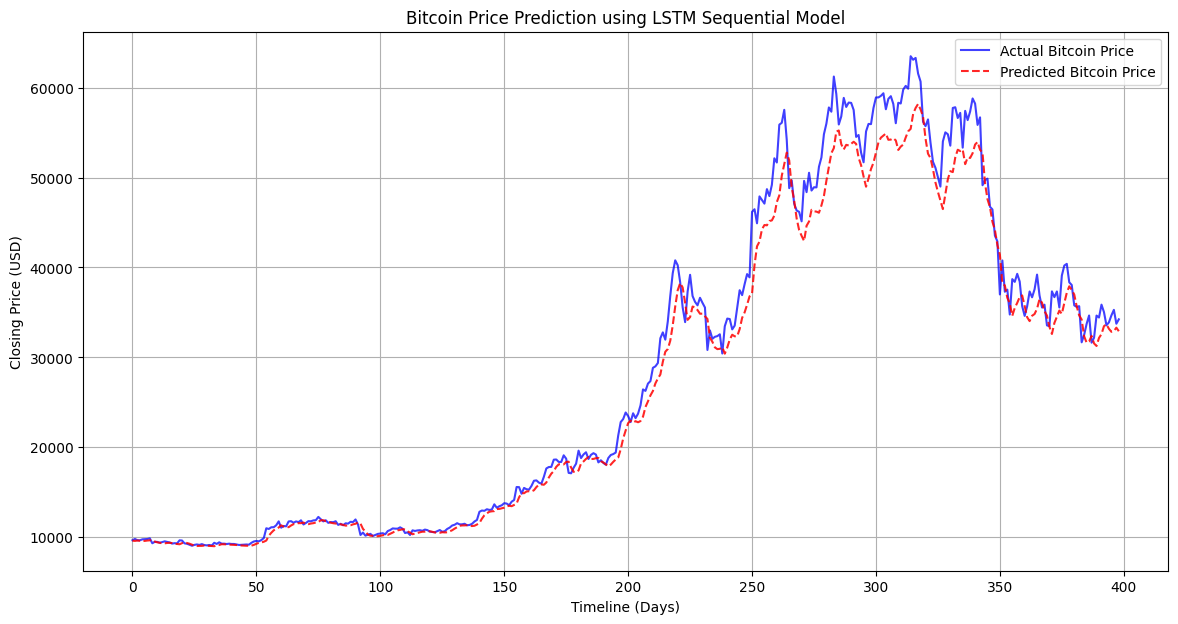

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --- Task 2: Create sliding-window sequences (previous 7 days) ---
window_size = 7
X = []
y = []

for i in range(len(scaled_close) - window_size):
    X.append(scaled_close[i : i + window_size])
    y.append(scaled_close[i + window_size])

X = np.array(X)
y = np.array(y)

print(f"Sequence shapes -> X: {X.shape}, y: {y.shape}")

# --- Task 4: Chronological Train-Test Split (80% train, 20% test) ---
split_index = int(len(X) * 0.8)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

# --- Task 3: Select and Justify sequential model ---
# Justification:
# An LSTM (Long Short-Term Memory) network is chosen over a Simple RNN because it addresses
# the vanishing gradient problem, allowing the model to capture long-term chronological relationships
# and trends typical of financial time series data like cryptocurrency prices.

model = Sequential([
    LSTM(50, activation='tanh', input_shape=(window_size, 1), return_sequences=False),
    Dropout(0.1),
    Dense(25),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# Predict on the test set
predictions_scaled = model.predict(X_test)

# Inverse transform to get actual prices back from normalized scale
predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))

print(f"\nEvaluation Metrics on Unseen Test Data:")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

# --- Task 5: Plot actual versus predicted closing prices ---
plt.figure(figsize=(14, 7))
plt.plot(y_test_actual, label='Actual Bitcoin Price', color='blue', alpha=0.75)
plt.plot(predictions, label='Predicted Bitcoin Price', color='red', alpha=0.85, linestyle='--')
plt.title('Bitcoin Price Prediction using LSTM Sequential Model')
plt.xlabel('Timeline (Days)')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True)
plt.show()